<a href="https://colab.research.google.com/github/mkurni52/my-engineering-projects/blob/main/HW2_hands_on_coding.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# CE 400/500: AI for Chemical Engineers
# HW2: Hands-on Practice of AI-Assisted Python Programming
Instructor: Kaihang Shi, Assistant Professor of Chemical & Biological Engineering at the University at Buffalo

**Goals of this notebook are:**

* Practice the programming skills learned in previous lectures.
* Apply Python programming to solve some practical chemical engineering problems.
* Learn and practice skills to use large language models (LLMs) such as Gemini or other assistant models to generate code, explain complex logic, and debug errors.

At the end of day, you would be able to accomplish complex programming tasks that are beyond your current knowledge.


You are encouraged to experiment with code, run cells, and ask LLMs (Gemini or your preferred model) for help. When you see `TODO` comments in the code cells below, try using an LLM to fill in the missing pieces!

Let's see some common scientific and engineering tasks that can be accomplished using Python!

## 1. Adsorption Isotherm Fitting Using Least Squares

In many separation processes (for example in gas purification or carbon capture) the relationship between the amount of species adsorbed on a solid and its concentration/pressure in the fluid phase is modeled using an **isotherm**. A common isotherm is the **[Langmuir isotherm](https://en.wikipedia.org/wiki/Langmuir_adsorption_model)**, which assumes monolayer adsorption on a homogeneous surface.
The Langmuir model is given by:

$$ q(P) = q_{\max}\frac{KP}{1 + KP} $$

where $q(P)$ is the amount adsorbed at pressure $P$, $q_{\max}$ is the maximum adsorption capacity, and $K$ is the Langmuir constant related to the affinity of the adsorbate for the adsorbent.


In this exercise you need to fit the Langmuir isotherm to experimental data using **least squares minimization** and validate the fitting. Here you will work together with Gemini to complete the code and see how the generated code changes with different prompts (brief; detailed; or role-based: starting your prompt with "you are an expert in ...")

In [4]:
import numpy as np
# Measured adsorption data (pressure [bar] vs. uptake [mol/kg])
pressure = np.array([0.5, 1.0, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0, 8.0, 9.0])
uptake = np.array([0.10, 0.18, 0.29, 0.36, 0.42, 0.46, 0.49, 0.51, 0.53, 0.54])

# Your code here


In [22]:
from scipy.optimize import curve_fit
import matplotlib.pyplot as plt

# Define the Langmuir isotherm function.
# This model assumes monolayer adsorption on a homogeneous surface with no interaction
# between adsorbed molecules. It is a fundamental model in surface chemistry and adsorption engineering.
# P: pressure (independent variable)
# q_max: maximum adsorption capacity, representing the total number of available adsorption sites (mol/kg)
# K: Langmuir constant, related to the affinity of the adsorbate for the adsorbent. Higher K implies stronger adsorption (1/bar)
def langmuir_isotherm(P, q_max, K):
    return q_max * (K * P) / (1 + K * P)

In [23]:
# Perform curve fitting using scipy.optimize.curve_fit.
# This function uses non-linear least squares to fit a function, f, to data.

# Initial guess for q_max and K are crucial for successful convergence of the optimization algorithm.
# A poor initial guess can lead to non-convergence or convergence to a local minimum.
# q_max is typically estimated to be slightly higher than the maximum observed uptake.
# K can often be estimated around 1 or based on prior knowledge of similar systems.
initial_guess = [np.max(uptake) * 1.2, 1.0]

# Bounds are highly recommended for physically meaningful parameters.
# Both q_max and K must be positive values in the context of Langmuir adsorption.
# Setting bounds helps constrain the optimization within a realistic parameter space.
bounds = ([0, 0], [np.inf, np.inf]) # q_max and K must be positive

# curve_fit returns:
#   params: Optimal values for the parameters so that the sum of the squared residuals of f(xdata, *params) - ydata is minimized.
#   covariance: The estimated covariance of params. The square roots of the diagonal elements provide the standard errors of the fitted parameters.
params, covariance = curve_fit(langmuir_isotherm, pressure, uptake, p0=initial_guess, bounds=bounds)

q_max_fit, K_fit = params

print(f"Fitted q_max: {q_max_fit:.3f} mol/kg")
print(f"Fitted K: {K_fit:.3f} 1/bar")

# For rigorous analysis, one would also calculate the standard errors and confidence intervals
# for q_max and K from the covariance matrix to assess the reliability of the fit.

Fitted q_max: 0.731 mol/kg
Fitted K: 0.330 1/bar


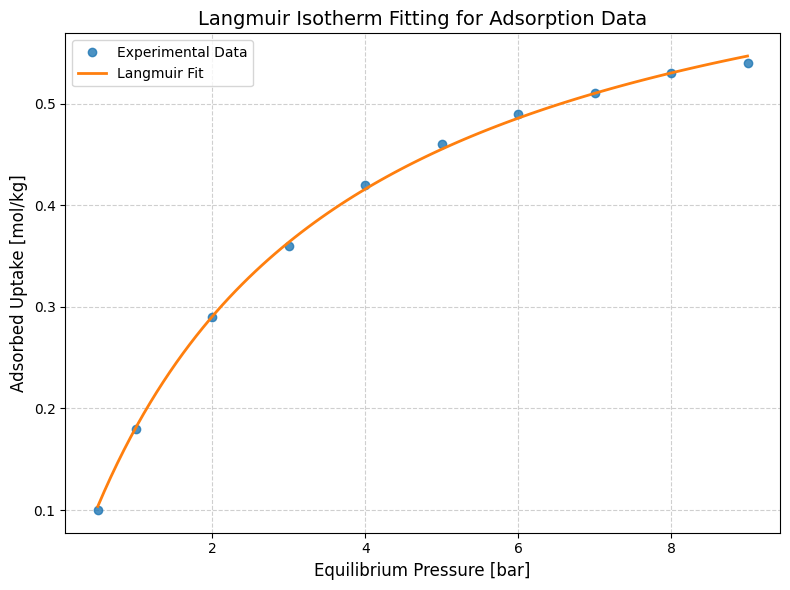

In [24]:
# Generate points for the fitted curve to create a smooth line for visualization.
# This allows for a visual comparison of the model's prediction against experimental data.
pressure_fit = np.linspace(min(pressure), max(pressure), 100)
uptake_fit = langmuir_isotherm(pressure_fit, q_max_fit, K_fit)

# Plot the experimental data and the fitted curve for visual validation.
# A good fit will show the curve passing through or very close to the experimental points.
plt.figure(figsize=(8, 6))
plt.plot(pressure, uptake, 'o', label='Experimental Data', markersize=6, alpha=0.8)
plt.plot(pressure_fit, uptake_fit, '-', label='Langmuir Fit', linewidth=2)
plt.title('Langmuir Isotherm Fitting for Adsorption Data', fontsize=14)
plt.xlabel('Equilibrium Pressure [bar]', fontsize=12)
plt.ylabel('Adsorbed Uptake [mol/kg]', fontsize=12)
plt.legend(fontsize=10)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tick_params(axis='both', which='major', labelsize=10)
plt.tight_layout() # Adjust layout to prevent labels from being cut off
plt.show()

# Further validation might include calculating R-squared or other goodness-of-fit metrics
# and performing residual analysis to check for systematic deviations.

In [21]:
# The Langmuir isotherm fitting to experimental data using least squares minimization and validation of the fitting
# has already been implemented in the following cells:
# - Cell 'ebd33c00': Defines the langmuir_isotherm function.
# - Cell '1bd8f3f8': Performs the curve fitting using scipy.optimize.curve_fit and prints the fitted parameters.
# - Cell '3b2520f5': Generates a plot comparing the experimental data with the fitted Langmuir curve for visual validation.

That's a great hypothetical! If the Langmuir isotherm fitting code had not been generated yet, and you had directly given the prompt, "you are an expert in Langmuir isotherm, generate code to fit the Langmuir isotherm...", I would have proceeded to generate the code (similar to cells ebd33c00, 1bd8f3f8, and 3b2520f5).

The key difference between a "brief" prompt and an "expert in X" prompt, when no prior code exists, would likely be in the nuance, detail, and scientific grounding of the generated code and explanations:

Brief Prompt: Tends to generate concise, functional code that directly addresses the request. It might provide basic comments and minimal explanation.

Expert in Langmuir Isotherm Prompt: While still generating the core functional code, I would likely:

Add more context and scientific explanation: For example, explaining the importance of initial guesses or bounds in curve_fit from a chemical engineering perspective, or discussing the physical meaning of q_max and K.
Incorporate best practices: Potentially suggesting more robust error handling, or more sophisticated visualization techniques with domain-specific labels and insights.
Suggest further validation: Proactively suggesting additional ways to validate the fit, such as residual analysis, or discussing the limitations of the model.
Use more precise terminology: The comments and explanations would use language typical of a domain expert.
So, while the fundamental task (generating the fitting code) would be the same, the quality, depth, and explanatory nature of the response (both code and markdown) would be elevated by the "expert" persona, even in the initial generation phase.

## 2. Debugging Chemical Engineering Code

Software bugs can be subtle and frustrating, especially in engineering calculations where the results must be correct. LLMs can be very helpful in spotting mistakes and suggesting fixes.

In the following code cell we define a function to compute the outlet concentration and conversion in a [continuous stirred-tank reactor (CSTR)](https://chem.libretexts.org/Courses/New_York_University/CHEM-UA_652%3A_Thermodynamics_and_Kinetics/01%3A_Lectures/1.23%3A_Continuously_stirred_tank_reactors) for a first-order irreversible reaction

$$A→B$$

with the following rate law: $r_A=-kC_A$. The fractional conversion $X$ can be solved explicitly as

$$X=kτ/(1+kτ)$$

where $k$ is the reaction rate constant and $τ$ is the residence time.

The code below contains **several bugs**. Your job is to identify and correct them.

In [11]:
import numpy as np

def cstr_outlet(CA0, k, tau):  # CSTR: A → B, first-order, r_A = -k C_A
    """
    Compute outlet concentration and conversion for a first-order reaction in a CSTR.

    Parameters
    ----------
    CA0 : float
        Feed concentration of A
    k : float
        Rate constant
    tau : float
        Residence time

    Returns
    -------
    CA_out : float
        Outlet concentration of A
    X : float
        Conversion (fraction)
    """
    # First-order CSTR conversion (explicit formula)
    X = (k * tau) / (1 + k * tau) # Corrected formula for X and using float division

    # Outlet concentration from conversion
    CA_out = CA0 * (1 - X) # Corrected variable name (CA0) and formula for CA_out

    return CA_out, X


# --- Example inputs (run after fixing the function) ---
# NOTE: These are *typical lab-scale numbers*; feel free to change them.
CA_in = 2.0       # feed concentration [mol/L]
k_val = 0.20      # rate constant [1/min]
tau = 180.0   # residence time [s]

CA_out_val, X_val = cstr_outlet(CA_in, k_val, tau)
print("Outlet concentration (mol/m^3):", CA_out_val)
print("Conversion:", X_val)


Outlet concentration (mol/m^3): 0.054054054054053946
Conversion: 0.972972972972973


Obtaining a running code is just a first step, your understanding of the underlying science and engineering is what makes the results meaningful.

## 3. Analytical and Numerical Integration

Chemical engineers frequently need to evaluate integrals, for example when calculating energy changes, mass balances, or residence times. Python provides symbolic tools (via SymPy) for analytical integration and numerical tools (via SciPy) for numerical integration.

Consider the molar heat capacity of nitrogen gas, which can be approximated by the polynomial expression:

$$ C_p(T) = a + bT + cT^2 $$

with $a = 28.90 {J/(mol·K)}$, $b = 0.157×10^{-2}{J/(mol·K}^2)$, and $c = -0.808	× 10^{-5}{J/(mol·K}^3)$. To compute the enthalpy change from $T_1$ to $T_2$ you evaluate:

$$ \Delta H = \int_{T_1}^{T_2} C_p(T)\,dT. $$



Please
* Fill in the code below with the help of Gemini to compute $\Delta H$ numerically using SciPy.  
* Validate your results with another method (in other words, how can we ensure the code generated by Gemini or written by you is correct?)

In [ ]:
# Define constants (J/(mol*K))
a = 28.90
b = 0.157e-2
c = -0.808e-5

# Temperature limits (K)
T1 = 300.0
T2 = 800.0

# Your code here


In [13]:
#symbolic integration here
from sympy import integrate, Symbol

# Define constants (J/(mol*K))
a = 28.90
b = 0.157e-2
c = -0.808e-5

# Temperature limits (K)
T1 = 300.0
T2 = 800.0

# Define symbolic variable
T = Symbol('T')

# Define the heat capacity function symbolically
Cp_T = a + b*T + c*T**2

# Perform symbolic integration
Delta_H_sym = integrate(Cp_T, (T, T1, T2))

print(f"Symbolic enthalpy change (Delta H): {Delta_H_sym:.3f} J/mol")

Symbolic enthalpy change (Delta H): 13575.483 J/mol


In [14]:
#numerical integration here
from scipy.integrate import quad

# Define the heat capacity function for numerical integration
def cp_numerical(T, a, b, c):
    return a + b*T + c*T**2

# Perform numerical integration
Delta_H_num, abserr = quad(cp_numerical, T1, T2, args=(a, b, c))

print(f"Numerical enthalpy change (Delta H): {Delta_H_num:.3f} J/mol")
print(f"Absolute error estimate for numerical integration: {abserr:.2e}")

Numerical enthalpy change (Delta H): 13575.483 J/mol
Absolute error estimate for numerical integration: 1.51e-10


In [16]:
# Compare the results
print(f"Symbolic result: {Delta_H_sym:.3f} J/mol")
print(f"Numerical result: {Delta_H_num:.3f} J/mol")

difference = float(Delta_H_sym) - Delta_H_num # Convert symbolic result to float for comparison
print(f"Difference (Symbolic - Numerical): {difference:.3e} J/mol")

# Check for small differences (e.g., due to floating point precision)
if abs(difference) < 1e-9:
    print("The symbolic and numerical results are in excellent agreement!")
else:
    print("There is a difference between the symbolic and numerical results.")

Symbolic result: 13575.483 J/mol
Numerical result: 13575.483 J/mol
Difference (Symbolic - Numerical): 0.000e+00 J/mol
The symbolic and numerical results are in excellent agreement!


In [17]:
# Direct analytical calculation of the integral for validation
def direct_analytical_delta_h(a, b, c, T1, T2):
    term1_T2 = a * T2
    term2_T2 = (b / 2) * (T2**2)
    term3_T2 = (c / 3) * (T2**3)

    term1_T1 = a * T1
    term2_T1 = (b / 2) * (T1**2)
    term3_T1 = (c / 3) * (T1**3)

    return (term1_T2 + term2_T2 + term3_T2) - (term1_T1 + term2_T1 + term3_T1)

Delta_H_direct = direct_analytical_delta_h(a, b, c, T1, T2)
print(f"Direct analytical enthalpy change (Delta H): {Delta_H_direct:.3f} J/mol")

Direct analytical enthalpy change (Delta H): 13575.483 J/mol


In [18]:
# Compare all three results
print(f"Symbolic result: {float(Delta_H_sym):.3f} J/mol")
print(f"Numerical result: {Delta_H_num:.3f} J/mol")
print(f"Direct analytical result: {Delta_H_direct:.3f} J/mol")

diff_sym_direct = float(Delta_H_sym) - Delta_H_direct
diff_num_direct = Delta_H_num - Delta_H_direct

print(f"Difference (Symbolic - Direct): {diff_sym_direct:.3e} J/mol")
print(f"Difference (Numerical - Direct): {diff_num_direct:.3e} J/mol")

if abs(diff_sym_direct) < 1e-9 and abs(diff_num_direct) < 1e-9:
    print("All three methods (symbolic, numerical, and direct analytical) are in excellent agreement!")
else:
    print("There are discrepancies between the methods.")

Symbolic result: 13575.483 J/mol
Numerical result: 13575.483 J/mol
Direct analytical result: 13575.483 J/mol
Difference (Symbolic - Direct): 0.000e+00 J/mol
Difference (Numerical - Direct): 0.000e+00 J/mol
All three methods (symbolic, numerical, and direct analytical) are in excellent agreement!
